# FBI over MCP

The two tools as a model sees them. [`client.ipynb`](client.ipynb) uses the
Python client directly; this goes through the server, which is what yada and
any agent will do.

**The server must be running and must be newer than the tools.** It does not
hot-reload: a server started before `fbi_offenses` existed serves the old tool
list, and the calls below fail as "unknown tool" rather than as anything that
explains itself. Restart it after pulling these changes.

In [1]:
%reload_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Anchor on this notebook's own directory rather than on the working directory:
# VS Code can root a notebook at the workspace folder instead of at the file,
# and then a relative "../" resolves somewhere else entirely and the imports
# below fail with ModuleNotFoundError.
_here = Path.cwd()
_FBI = _here if (_here / "utils" / "mcp.py").exists() else _here / "notebooks" / "fbi"
for _path in (str(_FBI), str(_FBI.parents[1])):      # notebooks/fbi, then the meida root
    if _path not in sys.path:
        sys.path.insert(0, _path)

from matplotlib import pyplot

from lib import config
from lib.utils import print_json_vertical
from utils.mcp import (call_tool, list_tools, observations, rolling_12,
                       clearance_rate, unfiled)

pyplot.style.use(config.glyfish_style)
for name, summary in await list_tools("fbi_"):
    print(f"{name:18} {summary}.")

fbi_offenses       Monthly offences known to law enforcement, or clearances of them, from the FBI Crime Data Explorer (1985 onwards).
fbi_employment     Annual sworn officers or civilian employees at ONE law-enforcement agency, from the FBI Crime Data Explorer (1985 onwards).


## Two tools, and why only two

FRED and CDC each carry six because they have category trees and dataset
vocabularies to walk. The FBI needs none: discovery goes through
`series_catalog_search`, which spans every source, so this source adds one tool
per retrieval route and nothing else.

    fbi_offenses(offense, scope, measure, unit, start, end)   monthly, 1985–
    fbi_employment(ori, measure, start, end)                  annual, 1985–

`scope` takes all three geographic grains as one string: `national`, a state
code, or an agency ORI.

In [2]:
national = await call_tool("fbi_offenses", {
    "offense": "homicide", "scope": "national", "measure": "offenses",
    "start": "01-2015", "end": "12-2024",
})
print_json_vertical({k: v for k, v in national.items()
                     if k not in ("observations", "population", "coverage")})

{
  "coverage_mean_percent": 94.55,
  "coverage_min_percent": 74.12,
  "coverage_min_period": "02-2021",
  "frequency": "Monthly",
  "geography": "United States",
  "last_refresh_date": "09/15/2026",
  "max_data_date": "09/2026",
  "measure": "offenses",
  "notices": [
    "This series spans 2021, when the FBI retired the Summary Reporting System for NIBRS. Two things changed at once: agencies that had not converted stopped reporting (the coverage dip), and NIBRS counts every offence in an incident where SRS counted only the most serious one. Treat the series as spliced, not continuous.",
    "Coverage bottoms out at 74.12% in 02-2021: that month's figure counts what was reported, not what happened."
  ],
  "observation_end": "12-2024",
  "observation_start": "01-2015",
  "offense": "homicide",
  "scope": "national",
  "unit": "count"
}


The series comes back alone — one call, one series, because the catalog entry
that sent you here describes one series. The payload the API returned held four
(offences and clearances, each as a count and a rate); `measure` and `unit`
selected among them here rather than in the request.

What rides along is context rather than data: the population denominator, the
reporting coverage, and the vintage.

## Coverage is the reason to trust or distrust a year

In [3]:
print(f"coverage: mean {national['coverage_mean_percent']}%, "
      f"minimum {national['coverage_min_percent']}% in {national['coverage_min_period']}")
for notice in national["notices"]:
    print(f"  notice: {notice}")

coverage: mean 94.55%, minimum 74.12% in 02-2021
  notice: This series spans 2021, when the FBI retired the Summary Reporting System for NIBRS. Two things changed at once: agencies that had not converted stopped reporting (the coverage dip), and NIBRS counts every offence in an incident where SRS counted only the most serious one. Treat the series as spliced, not continuous.
  notice: Coverage bottoms out at 74.12% in 02-2021: that month's figure counts what was reported, not what happened.


## The three grains

The same offence, at the nation, a state and a city department. Only the
`scope` string changes.

In [4]:
scopes = {"national": "United States", "DC": "District of Columbia",
          "DCMPD0000": "Washington PD"}
series = {}
for scope in scopes:
    series[scope] = await call_tool("fbi_offenses", {
        "offense": "homicide", "scope": scope, "measure": "offenses",
        "start": "01-2015", "end": "12-2024",
    })

for scope, label in scopes.items():
    points = observations(series[scope])
    total_2024 = sum(v for p, v in points.items() if p.endswith("2024"))
    print(f"  {label:22} {series[scope]['geography'][:34]:34} "
          f"2024 homicides {total_2024:>7,.0f}   coverage min "
          f"{series[scope]['coverage_min_percent']}%")

  United States          United States                      2024 homicides  17,261   coverage min 74.12%
  District of Columbia   District of Columbia               2024 homicides     181   coverage min 100.0%
  Washington PD          Washington Police Department       2024 homicides     181   coverage min 100.0%


DC's department reports fully throughout while the national series drops to
about 74% in 2021 — which is why a city series crosses that year more cleanly
than the national one, even though both are affected by the counting-rule
change NIBRS brought with it.

## Stance: the clearance rate

Clearances divided by offences is the standard measure of enforcement
intensity, and both come from the same tool. On a rolling year, because a
single month's ratio is meaningless: a clearance is recorded when it happens,
not when the offence it closes was committed.

In [5]:
offences = await call_tool("fbi_offenses", {
    "offense": "homicide", "scope": "DCMPD0000", "measure": "offenses",
    "start": "01-2015", "end": "12-2024"})
clearances = await call_tool("fbi_offenses", {
    "offense": "homicide", "scope": "DCMPD0000", "measure": "clearances",
    "start": "01-2015", "end": "12-2024"})

# Washington filed nothing from January to July 2021 while converting to
# NIBRS, and the API spells an unfiled month as 0. rolling_12 leaves out any
# window containing one rather than summing five filed months into a year.
missing = unfiled(observations(offences))
print("unfiled months:", ", ".join(sorted(missing, key=lambda p: (p[3:], p[:2]))) or "none")

rate = clearance_rate(rolling_12(observations(offences)),
                      rolling_12(observations(clearances)))
for period in ("12-2016", "12-2019", "12-2021", "12-2024"):
    reading = f"{rate[period]:5.1f}%" if period in rate else "    —  (a window with an unfiled month)"
    print(f"  {period}  clearance rate {reading}")

unfiled months: 01-2021, 02-2021, 03-2021, 04-2021, 05-2021, 06-2021, 07-2021
  12-2016  clearance rate  68.6%
  12-2019  clearance rate  68.1%
  12-2021  clearance rate     —  (a window with an unfiled month)
  12-2024  clearance rate  45.3%


## Capacity: officers at the same department

`fbi_employment` is agency-only — the national and state endpoints answer with
nulls — so a staffing panel is built department by department, pairing each
with `fbi_offenses` at the same ORI.

In [6]:
officers = await call_tool("fbi_employment", {"ori": "DCMPD0000", "measure": "officers"})
counts = observations(officers)
for year in ("1985", "1990", "2000", "2010", "2019", "2024"):
    if year in counts:
        print(f"  {year}  {counts[year]:>6,.0f} sworn officers")
for notice in officers.get("notices", []):
    print(f"  notice: {notice}")

  1985   3,837 sworn officers
  1990   4,740 sworn officers
  2000   3,628 sworn officers
  2010   3,945 sworn officers
  2019   3,809 sworn officers
  2024   3,276 sworn officers


## One department, both halves

Offences, clearance rate and staffing for the same city — the pairing the
enforcement question needs, from two tools and one API.

Text(0.995, 0.005, 'fbi_offenses(homicide, DCMPD0000, offenses|clearances) · fbi_employment(DCMPD0000)')

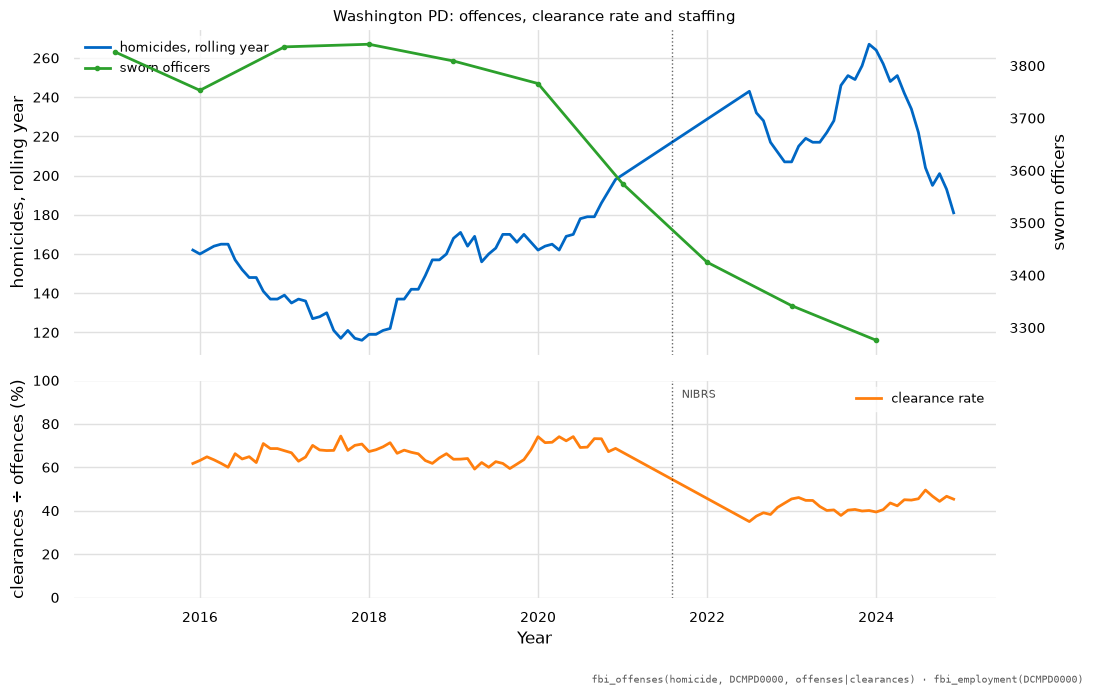

In [7]:
homicides = rolling_12(observations(offences))
months = sorted(homicides, key=lambda p: (p.split("-")[1], p.split("-")[0]))
as_year = lambda period: int(period.split("-")[1]) + (int(period.split("-")[0]) - 1) / 12

# Two panels rather than two lines on one axis: homicide counts run in the
# hundreds and a clearance rate runs 0-100, so sharing an axis flattens the
# rate into a line along the bottom and hides the thing worth seeing.
figure, (upper, lower) = pyplot.subplots(2, 1, figsize=(11, 7), sharex=True,
                                         gridspec_kw={"height_ratios": [3, 2]})

staff = upper.twinx()
staff.grid(False)
upper.plot([as_year(p) for p in months], [homicides[p] for p in months],
           lw=2, label="homicides, rolling year")
staff_years = sorted(int(y) for y in counts if 2015 <= int(y) <= 2024)
staff.plot(staff_years, [counts[str(y)] for y in staff_years], lw=2, color="tab:green",
           marker="o", markersize=3, label="sworn officers")
upper.set_ylabel("homicides, rolling year")
staff.set_ylabel("sworn officers")
lines = upper.get_lines() + staff.get_lines()
upper.legend(lines, [str(line.get_label()) for line in lines], loc="upper left", fontsize=9)
upper.set_title("Washington PD: offences, clearance rate and staffing", fontsize=11)

ordered = sorted(rate, key=lambda p: (p.split("-")[1], p.split("-")[0]))
lower.plot([as_year(p) for p in ordered], [rate[p] for p in ordered],
           lw=2, color="tab:orange", label="clearance rate")
lower.set_ylabel("clearances ÷ offences (%)")
lower.set_xlabel("Year")
lower.set_ylim(0, 100)
lower.legend(loc="upper right", fontsize=9)

for axis in (upper, lower):
    axis.axvline(2021.58, color="black", lw=1, ls=":", alpha=0.6)   # DC converted 2021-08
lower.text(2021.7, 92, "NIBRS", fontsize=8, alpha=0.7)

figure.tight_layout()
figure.subplots_adjust(bottom=0.13)
figure.text(0.995, 0.005,
            "fbi_offenses(homicide, DCMPD0000, offenses|clearances) · fbi_employment(DCMPD0000)",
            ha="right", va="bottom", fontsize=7, family="monospace", alpha=0.65)


The dotted line marks 2021, where the offence series is spliced — the FBI
retired the Summary Reporting System that January, and NIBRS counts every
offence in an incident where SRS counted only the most serious. The staffing
series is not affected by that change, which is part of why capacity is the
steadier of the two measures.

## Discovery goes through the catalog

These tools take ids, not searches. To find a series, ask the catalog, which
spans every source and routes each entry to whichever tool fetches it.

In [ ]:
import yaml

# The FBI is a live source, like FRED, BLS and BIS: its catalogue is the YAML
# under data/ that feeds the document store, and nothing about it is in
# Postgres. series_catalog_search covers the stored sources and will not find
# these, by design.
catalogue = sorted(Path(_FBI / "data").glob("fbi_series_*.yaml"))
total = 0
for path in catalogue:
    doc = yaml.safe_load(path.read_text())
    total += doc["series_count"]
print(f"{total:,} entries across {len(catalogue)} files")

entry = next(e for e in yaml.safe_load(catalogue[0].read_text())["series"]
             if e["facets"]["scope"] == "DCMPD0000")
print(f"\n  {entry['series_id']}")
print(f"  retrieval: {entry['retrieval']}")
print("\nretrieval minus 'tool' is the argument list for the calls above.")


The catalogue is not in the database and is not meant to be. A live source
keeps its metadata as files for the document store — `retrieval` minus `tool`
is still the argument list, whichever store the entry came from.
